# STAT 4710J — Midterm Review Code Practice


## 0. Environment Setup

In [7]:
!pip install matplotlib
!pip install seaborn
!pip install scipy
!pip install sklearn
!pip intall requests
!pip install bs4

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 4.5 MB/s  0:00:02 eta 0:00:01
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 2.6 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 3.1 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [matplotlib]7 [matplotlib]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.5/20.5 MB 3.7 MB/s  0:00:05 eta 0:00:01
  Installing build dependencies ... done
  Getting requirements to build wheel ... error
  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> [15 lines of output]
      The 'sklearn' PyPI package is deprecated, use 'scikit-learn'
      rather than 'sklearn' for pip commands.
      
      Here is how to fix this error in the main use cases:
      - use 'pip install scikit-learn' rather t

In [5]:
!pip install pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 4.0 MB/s  0:00:03eta 0:00:01


In [3]:
!pip install numpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 6.2 MB/s  0:00:01 eta 0:00:01


In [9]:
!pip install scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 4.6 MB/s  0:00:02 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [scikit-learn] [scikit-learn]


In [10]:
import re
import json
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from bs4 import BeautifulSoup
from scipy.stats import gaussian_kde
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import KFold
from sklearn.linear_model import Ridge, Lasso
from sklearn.metrics import mean_squared_error

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)

print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("Environment loaded successfully")

pandas: 3.1.1
numpy: 2.5.4
Environment loaded successfully


## 1. Data Fundamentals & EDA

**Corresponding RC material sections:** 1.1–1.7  


Variable types should be classified based on meaning, not only on the Python dtype.

In [2]:
records = pd.DataFrame({
    "device_id": ["d1", "d1", "d2", "d2"],
    "date": ["2026-01-01", "2026-01-02", "2026-01-01", "2026-01-02"],
    "temperature": [21.5, 22.0, 19.8, 20.1],
    "number_of_alerts": [0, 2, 1, 0],
    "satisfaction": ["low", "medium", "high", "medium"],
    "color": ["blue", "blue", "red", "green"]
})
display(records)

# device_id is not unique by itself; the combination (device_id, date) is unique
assert not records["device_id"].is_unique
assert not records.duplicated(["device_id", "date"]).any()
print("Is device_id unique by itself?", records["device_id"].is_unique)
print("Is the (device_id, date) combination unique?", not records.duplicated(["device_id", "date"]).any())

,device_id,date,temperature,number_of_alerts,satisfaction,color
0,d1,2026-01-01,21.5,0,low,blue
1,d1,2026-01-02,22.0,2,medium,blue
2,d2,2026-01-01,19.8,1,high,red
3,d2,2026-01-02,20.1,0,medium,green


Is device_id unique by itself? False
Is the (device_id, date) combination unique? True


Quick variable-type check:
- temperature: quantitative continuous
- number_of_alerts: quantitative discrete
- satisfaction: qualitative ordinal
- color: qualitative nominal

Sampling people who are easiest to reach is usually convenience sampling. It may involve both chance error and selection bias; increasing the sample size does not automatically eliminate selection bias.

## 2. Pandas I & II

**Corresponding RC Material sections:** 2.1–2.11  


In [11]:
staff_poll = pd.DataFrame({
    "name": ["Ava", "Ben", "Chen", "Dina", "Eli"],
    "flavor": ["citrus", "berry", "citrus", "mint", "berry"],
    "year": ["first", "second", "third", "second", "fourth"],
    "soda": ["Mountain Dew", "Cola", "Orange Soda", "Root Beer", "Lime"]
})
display(staff_poll)

,name,flavor,year,soda
0,Ava,citrus,first,Mountain Dew
1,Ben,berry,second,Cola
2,Chen,citrus,third,Orange Soda
3,Dina,mint,second,Root Beer
4,Eli,berry,fourth,Lime


In [21]:
fav_flavors = staff_poll["flavor"].value_counts()
fav_flavors

flavor
citrus    2
berry     2
mint      1
Name: count, dtype: int64

*Which of the following lines of code will visualize the data stored in fav_flavors?

<Axes: >

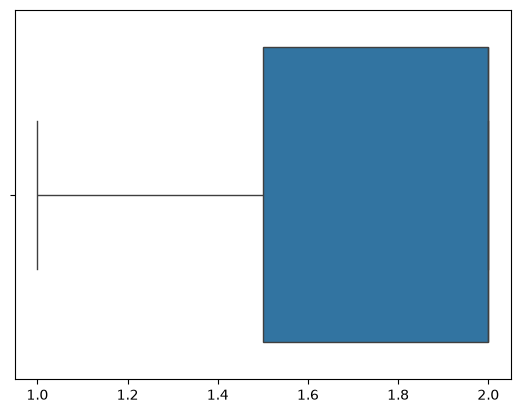

In [ ]:
#sns.countplot(data=staff_poll, x="flavor") 
#plt.hist(fav_flavors)
#sns.boxplot(x=fav_flavors.values)
#plt.bar(fav_flavors.index, fav_flavors.values)

In [ ]:
# .loc selects by label; .iloc selects by integer position
indexed = staff_poll.set_index("name")
by_label = indexed.loc["Ava":"Chen", ["flavor", "year"]]
by_position = indexed.iloc[0:3, 0:2] # right exclusive
display(by_label)
display(by_position)
assert list(by_label.index) == ["Ava", "Ben", "Chen"]
assert list(by_position.index) == ["Ava", "Ben", "Chen"]

,flavor,year
name,,
Ava,citrus,first
Ben,berry,second
Chen,citrus,third


,flavor,year
name,,
Ava,citrus,first
Ben,berry,second
Chen,citrus,third


In [23]:
university = pd.DataFrame({
    "School": ["North College", "East University", "West Institute", "South College"],
    "Tuition": [42000, 53000, 47000, 39000],
    "Accepted": ["1", "0", "1", "1"],
    "Degree Program": ["Computer Science", "Mathematics", "Computer Science", "History"],
    "Location": ["Lake City, North", "Easton, East", "Westport, West", "South Bay, South"]
})

# Boolean filtering: parenthesize each comparison and use & / | / ~
low_tuition = university[university["Tuition"] < 50000]
accepted = university[university["Accepted"] == "1"]  # Accepted is stored as str, don't forget the quotes
cs_and_accepted = university[
    (university["Degree Program"].str.contains("Computer Science", na=False)) &
    (university["Accepted"] == "1")
]
display(low_tuition)
display(accepted)
display(cs_and_accepted)
assert len(low_tuition) == 3
assert len(accepted) == 3
assert len(cs_and_accepted) == 2

,School,Tuition,Accepted,Degree Program,Location
0,North College,42000,1,Computer Science,"Lake City, North"
2,West Institute,47000,1,Computer Science,"Westport, West"
3,South College,39000,1,History,"South Bay, South"


,School,Tuition,Accepted,Degree Program,Location
0,North College,42000,1,Computer Science,"Lake City, North"
2,West Institute,47000,1,Computer Science,"Westport, West"
3,South College,39000,1,History,"South Bay, South"


,School,Tuition,Accepted,Degree Program,Location
0,North College,42000,1,Computer Science,"Lake City, North"
2,West Institute,47000,1,Computer Science,"Westport, West"


In [24]:
# String methods：split、contains、len
university["State"] = university["Location"].str.split(", ").str[1]
accepted = university[university["Accepted"] == "1"]
has_space = staff_poll["soda"].str.contains(" ", na=False)
long_multiword_sodas = staff_poll[
    has_space & (staff_poll["soda"].str.len() >= 4)
]
display(university[["School", "Location", "State"]])
display(long_multiword_sodas)
assert university["State"].tolist() == ["North", "East", "West", "South"]
assert len(long_multiword_sodas) == 3

,School,Location,State
0,North College,"Lake City, North",North
1,East University,"Easton, East",East
2,West Institute,"Westport, West",West
3,South College,"South Bay, South",South


,name,flavor,year,soda
0,Ava,citrus,first,Mountain Dew
2,Chen,citrus,third,Orange Soda
3,Dina,mint,second,Root Beer


### 2.7 GroupBy

In [92]:
sales.groupby("store")

In [ ]:
# GroupBy：agg、filter、size、count
sales = pd.DataFrame({
    "store": ["A", "A", "B", "B", "B", "C"],
    "product_type": ["tea", "coffee", "tea", "coffee", "tea", "coffee"],
    "region": ["North", "North", "South", "South", "South", "East"],
    "sales": [600, 550, 300, 450, 400, 200],
    "rating": [4.5, 4.0, 4.2, np.nan, 4.8, 3.9]
})

store_total = sales.groupby("store")["sales"].sum()
high_sales_stores = sales.groupby("store").filter(
    lambda group: group["sales"].sum() > 700
)
store_size = sales.groupby("store").size()
store_rating_count = sales.groupby("store")["rating"].count()

display(sales)
display("store_total")
display(store_total)
display("high_sales_stores")
display(high_sales_stores)
display("store_size")
display(store_size)
display("store_rating_count")
display(store_rating_count)

assert set(high_sales_stores["store"]) == {"A", "B"}
assert store_size.loc["B"] == 3
assert store_rating_count.loc["B"] == 2

,store,product_type,region,sales,rating
0,A,tea,North,600,4.5
1,A,coffee,North,550,4.0
2,B,tea,South,300,4.2
3,B,coffee,South,450,NaN
4,B,tea,South,400,4.8
5,C,coffee,East,200,3.9


'store_total'

store
A    1150
B    1150
C     200
Name: sales, dtype: int64

'high_sales_stores'

,store,product_type,region,sales,rating
0,A,tea,North,600,4.5
1,A,coffee,North,550,4.0
2,B,tea,South,300,4.2
3,B,coffee,South,450,NaN
4,B,tea,South,400,4.8


'store_size'

store
A    2
B    3
C    1
dtype: int64

'store_rating_count'

store
A    2
B    2
C    1
Name: rating, dtype: int64

In [93]:
something1 = sales.groupby("store").sum()
something2 = sales.groupby("store").first()
something3 = sales.groupby("store").last()
something4 = sales.groupby("store").count()
something5 = sales.groupby("store").agg({"sales": "sum", "rating": "count"})
something6 = sales.groupby("store").agg("max")
display(sales)
display(something1)
# display(something2)
# display(something3)
# display(something4)
# display(something5)
# display(something6)

,store,product_type,region,sales,rating
0,A,tea,North,600,4.5
1,A,coffee,North,550,4.0
2,B,tea,South,300,4.2
3,B,coffee,South,450,NaN
4,B,tea,South,400,4.8
5,C,coffee,East,200,3.9


,product_type,region,sales,rating
store,,,,
A,teacoffee,NorthNorth,1150,8.5
B,teacoffeetea,SouthSouthSouth,1150,9.0
C,coffee,East,200,3.9


In [ ]:
# Grouping by multiple columns, sorting, and Boolean logic
# Take a look
pies = pd.DataFrame({
    "flavor": ["apple", "apple", "berry", "berry", "citrus", "citrus"],
    "crust": ["flaky", "short", "flaky", "short", "flaky", "short"],
    "satisfaction": [4.2, 4.0, 4.8, 4.1, 3.9, 4.4],
    "open_face": [1, 0, 1, 0, 1, 0],
    "lattice": [0, 1, 0, 1, 0, 1]
})

top_combinations = (
    pies.groupby(["flavor", "crust"])["satisfaction"]
        .mean()
        .sort_values(ascending=False)
        .head(5)
)
all_open_face_without_lattice = (
    pies.loc[pies["open_face"] == 1, "lattice"].sum() == 0
)
display(pies)
display(top_combinations)
print("All open-face pies have no lattice?", all_open_face_without_lattice)
assert all_open_face_without_lattice

,flavor,crust,satisfaction,open_face,lattice
0,apple,flaky,4.2,1,0
1,apple,short,4.0,0,1
2,berry,flaky,4.8,1,0
3,berry,short,4.1,0,1
4,citrus,flaky,3.9,1,0
5,citrus,short,4.4,0,1


flavor  crust
berry   flaky    4.8
citrus  short    4.4
apple   flaky    4.2
berry   short    4.1
apple   short    4.0
Name: satisfaction, dtype: float64

All open-face pies have no lattice? True


In [10]:
# pivot_table
pivot = sales.pivot_table(
    index="store",
    columns="product_type",
    values="sales",
    aggfunc="mean"
)
display(pivot)

product_type,coffee,tea
store,,
A,550.0,600.0
B,450.0,350.0
C,200.0,NaN


### 2.9 Joining Tables: pd.merge

In [41]:
display(accepted)


,School,Tuition,Accepted,Degree Program,Location,State
0,North College,42000,1,Computer Science,"Lake City, North",North
2,West Institute,47000,1,Computer Science,"Westport, West",West
3,South College,39000,1,History,"South Bay, South",South


In [ ]:
# merge + groupby: find the highest-ranked school in each state
rankings = pd.DataFrame({
    "School": ["North College", "East University", "West Institute", "South College"],
    "Ranking": [35, 12, 28, 18]
})

def is_ideal_state(group):
    return group["Degree Program"].str.contains("Computer Science", na=False).any()

ideal_states = accepted.groupby("State").filter(is_ideal_state)["State"].unique()
ideal_schools = university[university["State"].isin(ideal_states)]
complete = ideal_schools.merge(
    right=rankings, how="inner", left_on="School", right_on="School"
) # merge ideal schools with rankings


display("ideal_schools")
display(ideal_schools)
display("complete")
display(complete)
display("best_by_state")
display(best_by_state)


'ideal_schools'

,School,Tuition,Accepted,Degree Program,Location,State
0,North College,42000,1,Computer Science,"Lake City, North",North
2,West Institute,47000,1,Computer Science,"Westport, West",West


'complete'

,School,Tuition,Accepted,Degree Program,Location,State,Ranking
0,North College,42000,1,Computer Science,"Lake City, North",North,35
1,West Institute,47000,1,Computer Science,"Westport, West",West,28


'best_by_state'

,School,Tuition,Accepted,Degree Program,Location,Ranking
State,,,,,,
North,North College,42000,1,Computer Science,"Lake City, North",35
West,West Institute,47000,1,Computer Science,"Westport, West",28


#### What if the merging key in school column is not unique?

In [72]:
display("rankings",rankings)
university_multiple = university[["School", "Tuition", "Accepted", "Degree Program"]]
university_multiple.loc[len(university_multiple)] = ["North College", 48000, "1", "Mathematics"]
display("university_multiple",university_multiple)
university_multiple.merge(rankings, on="School")
merge1 = university_multiple.merge(rankings, on="School", how="left")
display("merge1, how = left",merge1)
merge2 = university_multiple.merge(rankings, on="School", how="right")
display("merge2, how = right",merge2)
merge3 = university_multiple.merge(rankings, on="School", how="outer")
display("merge3, how = outer",merge3)
merge4 = university_multiple.merge(rankings, on="School", how="inner")
display("merge4, how = inner",merge4)



'rankings'

,School,Ranking
0,North College,35
1,East University,12
2,West Institute,28
3,South College,18


'university_multiple'

,School,Tuition,Accepted,Degree Program
0,North College,42000,1,Computer Science
1,East University,53000,0,Mathematics
2,West Institute,47000,1,Computer Science
3,South College,39000,1,History
4,North College,48000,1,Mathematics


'merge1, how = left'

,School,Tuition,Accepted,Degree Program,Ranking
0,North College,42000,1,Computer Science,35
1,East University,53000,0,Mathematics,12
2,West Institute,47000,1,Computer Science,28
3,South College,39000,1,History,18
4,North College,48000,1,Mathematics,35


... (2 outputs left out)

'merge3, how = outer'

,School,Tuition,Accepted,Degree Program,Ranking
0,East University,53000,0,Mathematics,12
1,North College,42000,1,Computer Science,35
2,North College,48000,1,Mathematics,35
3,South College,39000,1,History,18
4,West Institute,47000,1,Computer Science,28


'merge4, how = inner'

,School,Tuition,Accepted,Degree Program,Ranking
0,North College,42000,1,Computer Science,35
1,East University,53000,0,Mathematics,12
2,West Institute,47000,1,Computer Science,28
3,South College,39000,1,History,18
4,North College,48000,1,Mathematics,35


#### What if the merging key in both tables are not unique?

In [76]:

ratings = pd.DataFrame({
    "School": ["North College", "East University", "West Institute", "North College", "North College", "Nowhere University"],
    "Rating": [4.2, 3.8, 4.5, 4.0, 4.8, 0]
})
display("ratings",ratings)
display("university_multiple",university_multiple)
merge5 = university_multiple.merge(ratings, on="School", how="left")
display("merge5, how = left",merge5)
merge6 = university_multiple.merge(ratings, on="School", how="right")
display("merge6, how = right",merge6)
merge7 = university_multiple.merge(ratings, on="School", how="outer")
display("merge7, how = outer",merge7) 
merge8 = university_multiple.merge(ratings, on="School", how="inner")
display("merge8, how = inner",merge8)

'ratings'

,School,Rating
0,North College,4.2
1,East University,3.8
2,West Institute,4.5
3,North College,4.0
4,North College,4.8
5,Nowhere University,0.0


'university_multiple'

,School,Tuition,Accepted,Degree Program
0,North College,42000,1,Computer Science
1,East University,53000,0,Mathematics
2,West Institute,47000,1,Computer Science
3,South College,39000,1,History
4,North College,48000,1,Mathematics


'merge5, how = left'

,School,Tuition,Accepted,Degree Program,Rating
0,North College,42000,1,Computer Science,4.2
1,North College,42000,1,Computer Science,4.0
2,North College,42000,1,Computer Science,4.8
3,East University,53000,0,Mathematics,3.8
4,West Institute,47000,1,Computer Science,4.5
5,South College,39000,1,History,NaN
6,North College,48000,1,Mathematics,4.2
7,North College,48000,1,Mathematics,4.0
8,North College,48000,1,Mathematics,4.8


... (2 outputs left out)

'merge7, how = outer'

,School,Tuition,Accepted,Degree Program,Rating
0,East University,53000.0,0,Mathematics,3.8
1,North College,42000.0,1,Computer Science,4.2
2,North College,42000.0,1,Computer Science,4.0
3,North College,42000.0,1,Computer Science,4.8
4,North College,48000.0,1,Mathematics,4.2
5,North College,48000.0,1,Mathematics,4.0
6,North College,48000.0,1,Mathematics,4.8
7,Nowhere University,NaN,NaN,NaN,0.0
8,South College,39000.0,1,History,NaN
9,West Institute,47000.0,1,Computer Science,4.5


'merge8, how = inner'

,School,Tuition,Accepted,Degree Program,Rating
0,North College,42000,1,Computer Science,4.2
1,North College,42000,1,Computer Science,4.0
2,North College,42000,1,Computer Science,4.8
3,East University,53000,0,Mathematics,3.8
4,West Institute,47000,1,Computer Science,4.5
5,North College,48000,1,Mathematics,4.2
6,North College,48000,1,Mathematics,4.0
7,North College,48000,1,Mathematics,4.8


Pandas section check:
1. `.loc` selects by label; `.iloc` selects by integer position.
2. Use `&` / `|` for multiple conditions and put parentheses around each comparison.
3. `filter` retains all original rows from qualifying groups; `agg` compresses each group into summary results.
4. `size()` counts rows; `count()` counts non-missing values.
5. After `merge`, check the row count and join-key uniqueness.

## 3. Text Data — String Methods & Regular Expressions

**Corresponding Word sections:** 3.1–3.8  

### 3.3 Regex

In [77]:
sample = "Some people like Diet Coke or Cherry Coke more than regular Coca-Cola"
patterns = {
    "coke_or_coca_cola": r"Coke|Coca-Cola",
    "coke_or_coca_cola_wrong1": r"Co[ke|ca\-Cola]",
    "coke_or_coca_cola_wrong2": r"Co(ke|ca-Cola)",
    "two_uppercase_and_four_digits": r"[A-Z]{2}-\d{4}",
    "emoji_names": r":([^:]*):"
}
print(re.findall(patterns["coke_or_coca_cola"], sample))
print(re.findall(patterns["coke_or_coca_cola_wrong1"], sample))
print(re.findall(patterns["coke_or_coca_cola_wrong2"], sample))
print(re.findall(patterns["two_uppercase_and_four_digits"], "IDs: AB-4821 and CD-9300"))
print(re.findall(patterns["emoji_names"], "Hello :wave: and :smile:"))
assert re.findall(patterns["emoji_names"], "Hello :wave: and :smile:") == ["wave", "smile"]

['Coke', 'Coke', 'Coca-Cola']
['Cok', 'Cok', 'Coc', 'Col']
['ke', 'ke', 'ca-Cola']
['AB-4821', 'CD-9300']
['wave', 'smile']


### 3.6 capture group

In [13]:
# findall: returns capture-group contents when capture groups are present
text = "sensor=AB-4821; backup=CD-9300"
with_groups = re.findall(r"([A-Z]{2})-(\d{4})", text)
without_groups = re.findall(r"[A-Z]{2}-\d{4}", text)
print("with groups:", with_groups)
print("without groups:", without_groups)
assert with_groups == [("AB", "4821"), ("CD", "9300")]
assert without_groups == ["AB-4821", "CD-9300"]

with groups: [('AB', '4821'), ('CD', '9300')]
without groups: ['AB-4821', 'CD-9300']


In [14]:
# Pandas Regex methods
s = pd.Series(["Event at 07:18:42", "Event at 12:05:09", "No timestamp"])
contains_time = s.str.contains(r"\d{2}:\d{2}:\d{2}", na=False)
extracted_time = s.str.extract(r"(\d{2}):(\d{2}):(\d{2})")
all_numbers = s.str.findall(r"\d+")
display(contains_time)
display(extracted_time)
display(all_numbers)

0     True
1     True
2    False
dtype: bool

,0,1,2
0,07,18,42
1,12,05,09
2,NaN,NaN,NaN


0    [07, 18, 42]
1    [12, 05, 09]
2              []
dtype: object

## 4. Text Representation & Embeddings

**Corresponding Word sections:** 4.1–4.8  


In [15]:
documents = [
    "data helps teams",
    "teams need context",
    "data needs context"
]
vectorizer = CountVectorizer()
bow_matrix = vectorizer.fit_transform(documents)
vocabulary = vectorizer.get_feature_names_out()
bow_df = pd.DataFrame(bow_matrix.toarray(), columns=vocabulary)
print("Vocabulary:", list(vocabulary))
display(bow_df)
assert bow_df.shape[1] == len(set(" ".join(documents).split()))

Vocabulary: ['context', 'data', 'helps', 'need', 'needs', 'teams']


,context,data,helps,need,needs,teams
0,0,1,1,0,0,1
1,1,0,0,1,0,1
2,1,1,0,0,1,0


In [16]:
# Manually calculate TF, DF, IDF, and TF-IDF (base-2)
corpus = ["red fox red", "blue fox", "red bird"]

def tf_idf(term, document, all_documents):
    tokens = document.split()
    tf = tokens.count(term) / len(tokens)
    df = sum(term in set(doc.split()) for doc in all_documents)
    idf = np.log2(len(all_documents) / df)
    return tf, df, idf, tf * idf

tf, df_term, idf, score = tf_idf("red", corpus[0], corpus)
print({"TF": tf, "DF": df_term, "IDF": idf, "TF-IDF": score})
assert np.isclose(tf, 2/3)
assert df_term == 2
assert np.isclose(idf, np.log2(3/2))

{'TF': 0.6666666666666666, 'DF': 2, 'IDF': np.float64(0.5849625007211562), 'TF-IDF': np.float64(0.3899750004807708)}


In [17]:
def cosine_similarity(u, v):
    u = np.asarray(u, dtype=float)
    v = np.asarray(v, dtype=float)
    return np.dot(u, v) / (np.linalg.norm(u) * np.linalg.norm(v))

vectors = {"A": [1, 0], "B": [1, 1], "C": [0, 1]}
for left, right in [("A", "B"), ("A", "C"), ("B", "C")]:
    print(left, right, cosine_similarity(vectors[left], vectors[right]))
assert np.isclose(cosine_similarity(vectors["A"], vectors["C"]), 0)

A B 0.7071067811865475
A C 0.0
B C 0.7071067811865475


Word2Vec concept check:
- CBOW: predicts the center word from context words.
- Skip-Gram: predicts surrounding context words from the center word.
- BoW / TF-IDF are count-based representations; Word2Vec is a distributed vector representation learned from context.
- GPT autoregressive generation: predict the next token step by step, add it to the context, and continue generating.

## 5. Data on the Internet — HTTP, APIs, HTML & BeautifulSoup

**Corresponding Word sections:** 5.1–5.9  


In [18]:
json_text = '''
{"course": "STAT4710J", "week": 5, "topics": ["regex", "text data"], "active": true}
'''
data = json.loads(json_text)
print(data["course"], data["topics"])
assert data["week"] == 5

STAT4710J ['regex', 'text data']


In [19]:
# requests example (not executed by default)
# Uncomment when scraping, and follow API, robots, and rate-limit rules.
#
# url = "https://example.com"
# response = requests.get(url, timeout=10)
# response.raise_for_status()
# html_text = response.text
#
# HTTP 429 usually indicates too many requests or rate limiting.
print("This Notebook does not automatically make external network requests.")

This Notebook does not automatically make external network requests.


In [20]:
html = '''
<html>
  <body>
    <div class="catalog">
      <div class="product"><h2>Notebook Stand</h2><a href="/item/17">Details</a></div>
      <div class="product"><h2>Desk Lamp</h2><a href="/item/28">Details</a></div>
    </div>
    <footer>End</footer>
  </body>
</html>
'''
soup = BeautifulSoup(html, "html.parser")
products = soup.find_all("div", attrs={"class": "product"})
product_rows = []
for product in products:
    product_rows.append({
        "title": product.find("h2").text.strip(),
        "href": product.find("a").get("href")
    })
product_df = pd.DataFrame(product_rows)
display(product_df)
assert len(products) == 2
assert product_df.loc[0, "href"] == "/item/17"

,title,href
0,Notebook Stand,/item/17
1,Desk Lamp,/item/28


In [21]:
# DOM children: count direct children only
body = soup.find("body")
direct_element_children = [
    child for child in body.find_all(recursive=False)
    if getattr(child, "name", None)
]
print("Direct element children:", [child.name for child in direct_element_children])
assert [child.name for child in direct_element_children] == ["div", "footer"]

Direct element children: ['div', 'footer']


## 6. Visualization

**Corresponding Word sections:** 6.1–6.12  

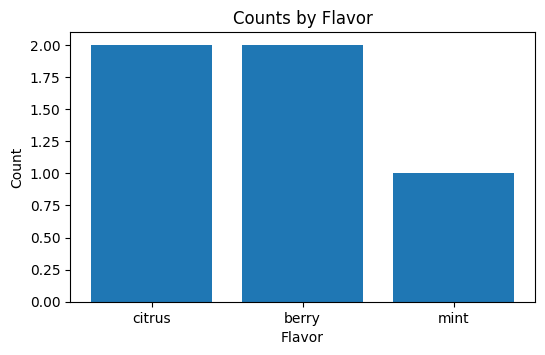

In [22]:
# Category frequencies: bar plot
flavor_counts = staff_poll["flavor"].value_counts()
plt.figure(figsize=(6, 3.5))
plt.bar(flavor_counts.index, flavor_counts.values)
plt.xlabel("Flavor")
plt.ylabel("Count")
plt.title("Counts by Flavor")
plt.show()

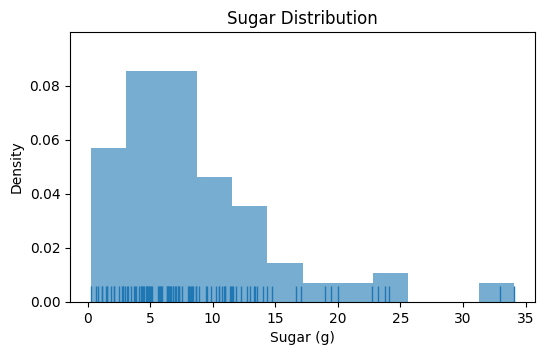

In [23]:
# Numeric distribution: histogram + rug plot
rng = np.random.default_rng(4710)
sugar = rng.gamma(shape=2.0, scale=4.0, size=100)
plt.figure(figsize=(6, 3.5))
plt.hist(sugar, bins=12, density=True, alpha=0.6)
sns.rugplot(x=sugar, height=0.06)
plt.xlabel("Sugar (g)")
plt.ylabel("Density")
plt.title("Sugar Distribution")
plt.show()

{'Q1': np.float64(4.327920546560153), 'Median': np.float64(6.899761911055815), 'Q3': np.float64(11.067910517086831), 'IQR': np.float64(6.739989970526678), 'Lower fence': np.float64(-5.782064409229863), 'Upper fence': np.float64(21.17789547287685)}


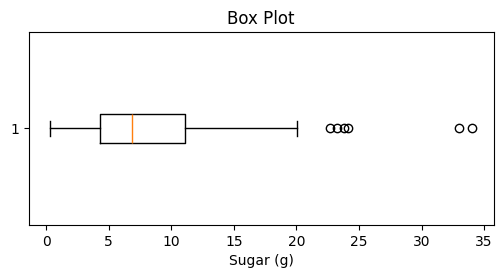

In [24]:
# Quartiles, IQR, and boxplot
q1 = np.quantile(sugar, 0.25)
median = np.quantile(sugar, 0.50)
q3 = np.quantile(sugar, 0.75)
iqr = q3 - q1
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr
print({"Q1": q1, "Median": median, "Q3": q3, "IQR": iqr,
       "Lower fence": lower_fence, "Upper fence": upper_fence})
plt.figure(figsize=(6, 2.5))
plt.boxplot(sugar, vert=False)
plt.xlabel("Sugar (g)")
plt.title("Box Plot")
plt.show()
assert np.isclose(iqr, q3 - q1)

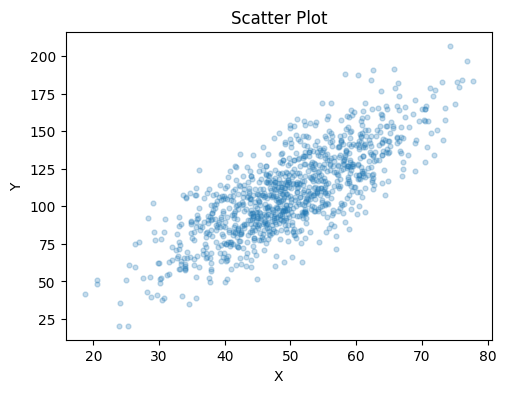

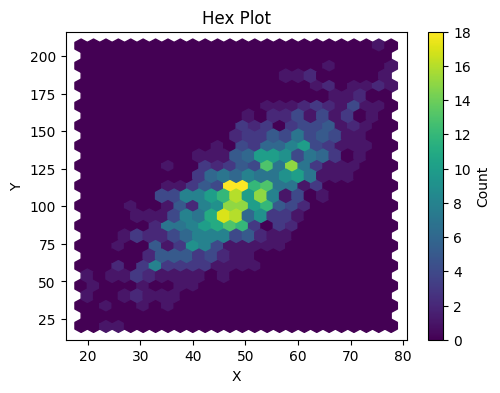

In [25]:
# Two continuous variables: scatter / hex plot
x = rng.normal(50, 10, 1000)
y = 2.2 * x + rng.normal(0, 18, 1000)

plt.figure(figsize=(5.5, 4))
plt.scatter(x, y, alpha=0.25, s=12)
plt.xlabel("X")
plt.ylabel("Y")
plt.title("Scatter Plot")
plt.show()

plt.figure(figsize=(5.5, 4))
plt.hexbin(x, y, gridsize=25)
plt.xlabel("X")
plt.ylabel("Y")
plt.title("Hex Plot")
plt.colorbar(label="Count")
plt.show()

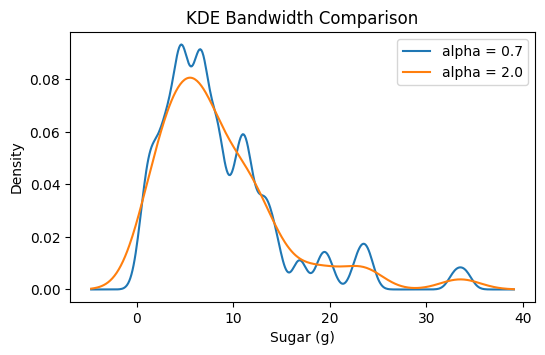

Approximate density area: 0.999722434868309


/tmp/ipykernel_1069/1825350762.py:21: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  area = np.trapz(density_large, grid)


In [26]:
# Implement Gaussian KDE manually: larger alpha produces a smoother curve
def gaussian_kde_manual(data, grid, alpha):
    data = np.asarray(data)
    z = (grid[:, None] - data[None, :]) / alpha
    kernels = np.exp(-0.5 * z**2) / np.sqrt(2 * np.pi)
    return kernels.sum(axis=1) / (len(data) * alpha)

grid = np.linspace(sugar.min() - 5, sugar.max() + 5, 400)
density_small = gaussian_kde_manual(sugar, grid, alpha=0.7)
density_large = gaussian_kde_manual(sugar, grid, alpha=2.0)

plt.figure(figsize=(6, 3.5))
plt.plot(grid, density_small, label="alpha = 0.7")
plt.plot(grid, density_large, label="alpha = 2.0")
plt.xlabel("Sugar (g)")
plt.ylabel("Density")
plt.title("KDE Bandwidth Comparison")
plt.legend()
plt.show()

area = np.trapz(density_large, grid)
print("Approximate density area:", area)

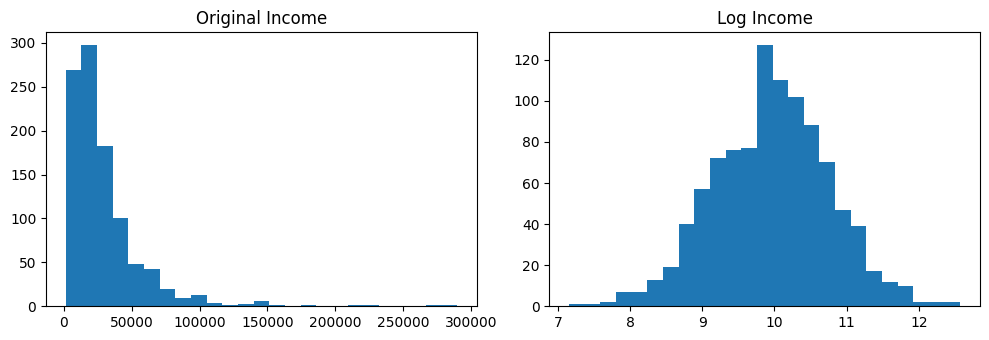

In [27]:
# Log transformation: compress larger values
income = rng.lognormal(mean=10, sigma=0.8, size=1000)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist(income, bins=25)
axes[0].set_title("Original Income")
axes[1].hist(np.log(income), bins=25)
axes[1].set_title("Log Income")
plt.tight_layout()
plt.show()

## 7. SQL I & II

**Corresponding Word sections:** 7.1–7.12  


This section uses Python's built-in `sqlite3`; no external database connection is required.

In [78]:
conn = sqlite3.connect(":memory:")
conn.executescript('''
CREATE TABLE Customers (
    customer_id INTEGER PRIMARY KEY,
    customer_name TEXT,
    region TEXT
);
CREATE TABLE Orders (
    order_id INTEGER PRIMARY KEY,
    customer_id INTEGER,
    status TEXT,
    amount REAL,
    FOREIGN KEY(customer_id) REFERENCES Customers(customer_id)
);
INSERT INTO Customers VALUES
(1, 'Ava', 'North'), (2, 'Ben', 'South'),
(3, 'Chen', 'North'), (4, 'Dina', 'East');
INSERT INTO Orders VALUES
(101, 1, 'paid', 300), (102, 1, 'paid', 450),
(103, 2, 'paid', 200), (104, 2, 'pending', 120),
(105, 3, 'paid', 500), (106, 4, 'paid', 180);
''')
display(pd.read_sql_query("SELECT * FROM Orders", conn))

,order_id,customer_id,status,amount
0,101,1,paid,300.0
1,102,1,paid,450.0
2,103,2,paid,200.0
3,104,2,pending,120.0
4,105,3,paid,500.0
5,106,4,paid,180.0


In [ ]:
# WHERE + JOIN + GROUP BY + HAVING + ORDER BY
query = '''
SELECT C.region, COUNT(*) AS n_orders,
       AVG(O.amount) AS avg_amount, SUM(O.amount) AS total_amount
FROM Customers AS C
INNER JOIN Orders AS O ON C.customer_id = O.customer_id
WHERE O.status = 'paid'
GROUP BY C.region
HAVING COUNT(*) >= 1
ORDER BY avg_amount DESC;
'''
display(pd.read_sql_query(query, conn))

,region,n_orders,avg_amount,total_amount
0,North,3,416.666667,1250.0
1,South,1,200.000000,200.0
2,East,1,180.000000,180.0


In [30]:
# CASE WHEN
case_query = '''
SELECT customer_id, amount,
       CASE WHEN amount >= 300 THEN 'large'
            ELSE 'regular'
       END AS purchase_class
FROM Orders;
'''
display(pd.read_sql_query(case_query, conn))

,customer_id,amount,purchase_class
0,1,300.0,large
1,1,450.0,large
2,2,200.0,regular
3,2,120.0,regular
4,3,500.0,large
5,4,180.0,regular


In [31]:
# NULL: use IS NOT NULL
conn.execute("INSERT INTO Customers VALUES (5, NULL, 'West')")
nonnull_query = '''
SELECT * FROM Customers WHERE customer_name IS NOT NULL;
'''
display(pd.read_sql_query(nonnull_query, conn))
assert pd.read_sql_query(nonnull_query, conn)["customer_name"].notna().all()

,customer_id,customer_name,region
0,1,Ava,North
1,2,Ben,South
2,3,Chen,North
3,4,Dina,East


In [32]:
# GROUP BY, HAVING, ORDER BY, LIMIT, and IN subquery
conn.executescript('''
CREATE TABLE Cats (
    cat_id INTEGER PRIMARY KEY, owner_id INTEGER, age INTEGER, breed TEXT
);
INSERT INTO Cats VALUES
(1, 10, 2, 'tabby'), (2, 10, 5, 'tabby'),
(3, 11, 3, 'calico'), (4, 12, 1, 'siamese'),
(5, 12, 7, 'tabby'), (6, 12, 4, 'calico'),
(7, 13, 2, 'siamese');
''')

owners_with_multiple_cats = pd.read_sql_query('''
SELECT owner_id FROM Cats
WHERE age > 1
GROUP BY owner_id
HAVING COUNT(*) > 1;
''', conn)

top_owner = pd.read_sql_query('''
SELECT owner_id FROM Cats
GROUP BY owner_id
ORDER BY COUNT(*) DESC
LIMIT 1;
''', conn)

top_breeds = pd.read_sql_query('''
SELECT * FROM Cats
WHERE breed IN (
    SELECT breed FROM Cats
    GROUP BY breed
    ORDER BY COUNT(*) DESC
    LIMIT 2
);
''', conn)

display(owners_with_multiple_cats)
display(top_owner)
display(top_breeds)

,owner_id
0,10
1,12


,owner_id
0,12


,cat_id,owner_id,age,breed
0,1,10,2,tabby
1,2,10,5,tabby
2,4,12,1,siamese
3,5,12,7,tabby
4,7,13,2,siamese


In [33]:
# INNER JOIN + HAVING: retain only locations that appear in both tables
conn.executescript('''
CREATE TABLE Quests (
    quest_id INTEGER PRIMARY KEY, name TEXT, location TEXT, reward REAL
);
CREATE TABLE Travel (location TEXT PRIMARY KEY, travel_cost REAL);
INSERT INTO Quests VALUES
(1, 'Link', 'Forest', 300), (2, 'Zelda', 'Forest', 250),
(3, 'Impa', 'Castle', 200), (4, NULL, 'Castle', 100),
(5, 'Link', 'Village', 120);
INSERT INTO Travel VALUES
('Forest', 400), ('Castle', 250), ('Village', 80);
''')

best_quest = pd.read_sql_query('''
SELECT name, location, reward
FROM Quests
WHERE name IS NOT NULL
ORDER BY reward DESC
LIMIT 1;
''', conn)

location_summary = pd.read_sql_query('''
SELECT q.location, AVG(q.reward) AS avg_reward
FROM Quests AS q
INNER JOIN Travel AS t ON q.location = t.location
GROUP BY q.location, t.travel_cost
HAVING SUM(q.reward) > t.travel_cost;
''', conn)

display(best_quest)
display(location_summary)

,name,location,reward
0,Link,Forest,300.0


,location,avg_reward
0,Castle,150.0
1,Forest,275.0
2,Village,120.0


## 8. Machine Learning Supplement

**Corresponding Word sections:** 8.1–8.7  


This section is supplementary. Confirm whether it is covered this term before including it in the formal review.

In [34]:
# One-hot encoding and design matrix
categorical = pd.DataFrame({
    "product": ["A", "B", "C", "A", "B"],
    "shipping": ["fast", "slow", "standard", "slow", "fast"],
    "region": ["N", "S", "N", "E", "S"]
})
X_cat = pd.get_dummies(categorical, drop_first=True, dtype=int)
X_cat.insert(0, "intercept", 1)
display(X_cat)
print("Design matrix shape:", X_cat.shape)

,intercept,product_B,product_C,shipping_slow,shipping_standard,region_N,region_S
0,1,0,0,0,0,1,0
1,1,1,0,1,0,0,1
2,1,0,1,0,1,1,0
3,1,0,0,1,0,0,0
4,1,1,0,0,0,0,1


Design matrix shape: (5, 7)


In [35]:
# OLS: least-squares fitting
rng = np.random.default_rng(4710)
X = rng.normal(size=(100, 3))
true_beta = np.array([2.0, -1.5, 0.7])
y = 4.0 + X @ true_beta + rng.normal(scale=0.5, size=100)

X_design = np.column_stack([np.ones(len(X)), X])
beta_hat, residuals, rank, singular_values = np.linalg.lstsq(X_design, y, rcond=None)
y_hat = X_design @ beta_hat
mse = mean_squared_error(y, y_hat)

print("Estimated coefficients:", beta_hat)
print("Rank:", rank, "| Number of columns:", X_design.shape[1])
print("Training MSE:", mse)
assert rank == X_design.shape[1]

Estimated coefficients: [ 3.95961867  2.01371629 -1.40900144  0.6761119 ]
Rank: 4 | Number of columns: 4
Training MSE: 0.22127939872353283


In [36]:
# K-fold CV: number of candidate settings × number of folds
candidate_lambdas = [0.01, 0.1, 1.0, 10.0]
n_splits = 5
n_validation_scores = len(candidate_lambdas) * n_splits
print("Validation scores to calculate:", n_validation_scores)
assert n_validation_scores == 20

Validation scores to calculate: 20


In [37]:
# Ridge / LASSO: L2 and L1 penalties
ridge = Ridge(alpha=1.0).fit(X, y)
lasso = Lasso(alpha=0.1, max_iter=10000).fit(X, y)
print("Ridge coefficients:", ridge.coef_)
print("LASSO coefficients:", lasso.coef_)
print("LASSO exact zeros:", np.sum(np.isclose(lasso.coef_, 0)))

Ridge coefficients: [ 1.99644824 -1.39123721  0.6704923 ]
LASSO coefficients: [ 1.93231419 -1.27303979  0.59431346]
LASSO exact zeros: 0


Bias–Variance concept check:
- Bias: the model is too simple to capture the true relationship systematically; commonly associated with underfitting.
- Variance: the model is overly sensitive to changes in the training sample; commonly associated with overfitting.
- Decreasing training error alongside increasing validation error usually suggests overfitting.
- LASSO uses an L1 penalty and may shrink some coefficients to exactly 0; Ridge uses an L2 penalty and usually shrinks coefficients without making them exactly 0.